In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / 'cartpole.py').exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))          

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
import cartpole as cp

P = cp.CartPoleParams()
fn = cp.make_f(P)

In [10]:
def angle_pd(Kp, Kd):
    def u_fn(t, s):
        theta = s[2]          
        theta_dot = s[3]
        return Kp * theta + Kd * theta_dot           # F = Kp·θ + Kd·θ̇
    return u_fn

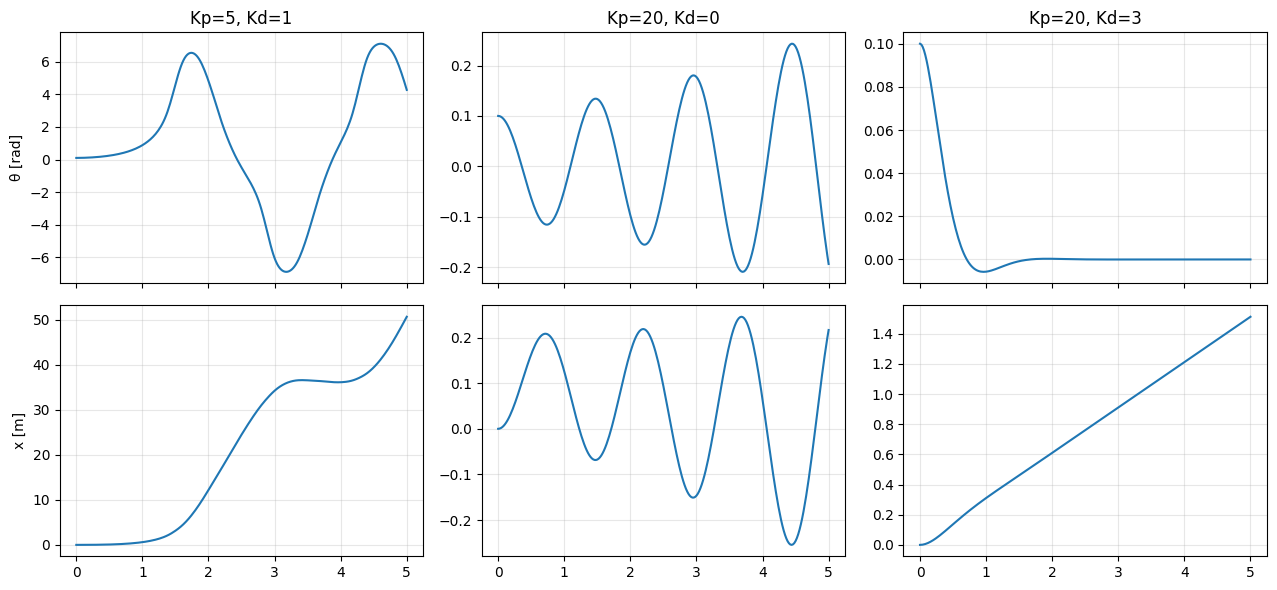

In [18]:
durumlar = [(5, 1), (20, 0), (20, 3)]
fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharex=True)

for j, (Kp, Kd) in enumerate(durumlar):
    t, S, U = cp.simulate(fn, [0, 0, 0.1, 0], angle_pd(Kp, Kd), dt=0.02, t_final=5.0, substeps=20)
    ax[0, j].plot(t, S[:, 2])            # üst satır: θ
    ax[1, j].plot(t, S[:, 0])            # alt satır: x
    ax[0, j].set_title(f"Kp={Kp}, Kd={Kd}")

ax[0, 0].set_ylabel("θ [rad]"); ax[1, 0].set_ylabel("x [m]")
for a in ax.flat: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [31]:
t, S, U = cp.simulate(fn, [0, 0, 0.1, 0], angle_pd(5, 1), dt=0.02, t_final=5.0, substeps=20)
HTML(cp.animate(t, S, P, U=U, show=False).to_jshtml())

# Arabayı da merkezde (x = 0) tutmak istesek ve F = K_p·θ + K_d·θ̇ + K_x·x şeklinde denesek:

In [24]:
def angle_pd_x(Kp, Kd, Kx):
    def u_fn(t, s):
        theta = s[2]          
        theta_dot = s[3]
        x = s[0]
        x_dot = s[1]
        return Kp * theta + Kd * theta_dot + Kx * x           # F = Kp·θ + Kd·θ̇ + Kx·x
    return u_fn

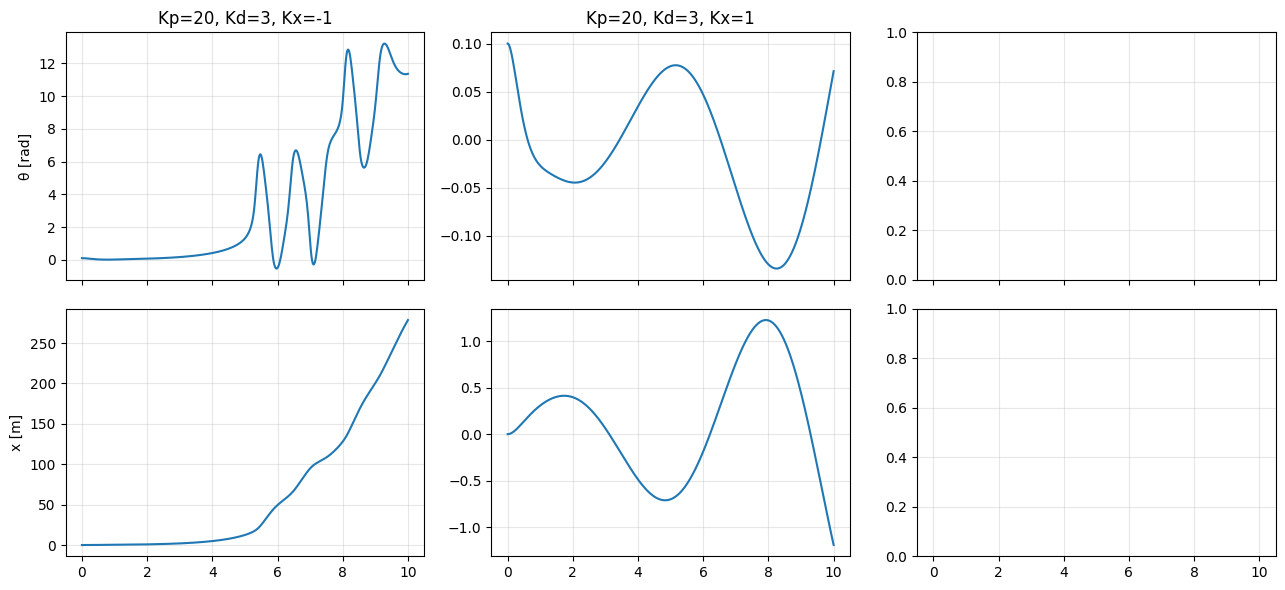

In [28]:
durumlar = [(20, 3, -1), (20, 3, 1)]
fig, ax = plt.subplots(2, 3, figsize=(13, 6), sharex=True)

for j, (Kp, Kd, Kx) in enumerate(durumlar):
    t, S, U = cp.simulate(fn, [0, 0, 0.1, 0], angle_pd_x(Kp, Kd, Kx), dt=0.02, t_final=10.0, substeps=20)
    ax[0, j].plot(t, S[:, 2])            # üst satır: θ
    ax[1, j].plot(t, S[:, 0])            # alt satır: x
    ax[0, j].set_title(f"Kp={Kp}, Kd={Kd}, Kx={Kx}")

ax[0, 0].set_ylabel("θ [rad]"); ax[1, 0].set_ylabel("x [m]")
for a in ax.flat: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [29]:
t, S, U = cp.simulate(fn, [0, 0, 0.1, 0], angle_pd_x(20, 3, -1), dt=0.02, t_final=5.0, substeps=20)
HTML(cp.animate(t, S, P, U=U, show=False).to_jshtml())

In [34]:
A, B = cp.analytic_AB(P)        # Aşama 2'deki doğrusal model (dik konum)

cases = [(5, 1, 0), (20, 0, 0), (20, 3, 0), (20, 3, -1), (20, 3, 1)]   # (Kp, Kd, Kx)
for Kp, Kd, Kx in cases:
    # x     ẋ    θ     θ̇        ← durum sırası: s = [x, ẋ, θ, θ̇]
    K = np.array([[-Kx,  0,  -Kp,  -Kd]])   # F = −K·s  →  kazançların eksisi
    eig = np.linalg.eigvals(A - B @ K)      # kapalı döngü matrisi
    print(f"Kp={Kp:>2}, Kd={Kd}, Kx={Kx:>2}:", np.round(eig, 3))

Kp= 5, Kd=1, Kx= 0: [ 0.     0.     2.547 -4.547]
Kp=20, Kd=0, Kx= 0: [0.+0.j    0.+0.j    0.+4.292j 0.-4.292j]
Kp=20, Kd=3, Kx= 0: [ 0.+0.j     0.+0.j    -3.+3.069j -3.-3.069j]
Kp=20, Kd=3, Kx=-1: [-2.84 +3.254j -2.84 -3.254j  0.878+0.j    -1.198+0.j   ]
Kp=20, Kd=3, Kx= 1: [-3.179+2.922j -3.179-2.922j  0.179+1.01j   0.179-1.01j ]


* (20, 0, 0) 0.+0.j    0.+0.j    0.+4.292j 0.-4.292j kararsız, "σ = 0, yani sınırda. Hiç pay olmadığı için gecikme onu kararsız yapar."
* (20, 3, 0) 0.+0.j     0.+0.j    -3.+3.069j -3.-3.069j kararlı, "Sarkaç kararlı, sistem bütün olarak değil." Kontrol mühendisliğinde bir sistemin asimptotik kararlı olması için bütün özdeğerlerin σ < 0 olması gerekir. Tek bir 0 bile bunu bozar. 
* (20, 3, −1)  -2.84 +3.254j -2.84 -3.254j  0.878+0.j    -1.198+0.j kararsız 0.8 yüzünden
* (20, 3, 1) -3.179+2.922j -3.179-2.922j  0.179+1.01j   0.179-1.01j 0.179+1.01j  kararsız 0.179-1.01j  yüzünden

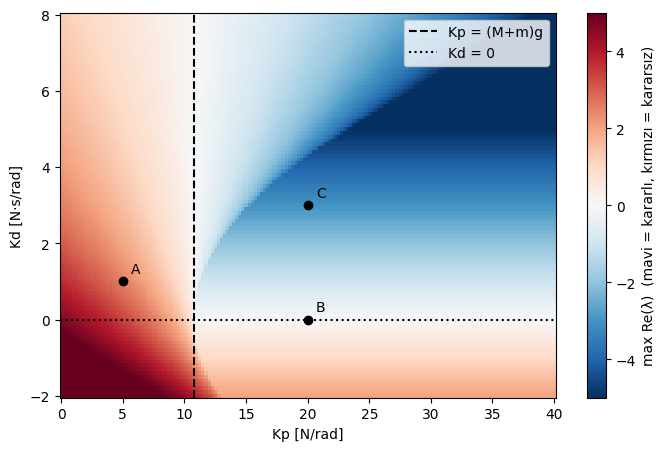

In [41]:
A_th = A[2:, 2:]
B_th = B[2:, :]

Kp_grid = np.linspace(0, 40, 161)
Kd_grid = np.linspace(-2, 8, 101)
sigma = np.zeros((len(Kd_grid), len(Kp_grid)))

for i, Kd in enumerate(Kd_grid):
    for j, Kp in enumerate(Kp_grid):
        K_th = np.array([[-Kp, -Kd]])                     # F = −K·s
        eig = np.linalg.eigvals(A_th - B_th @ K_th)       # A − BK
        sigma[i, j] = np.max(np.real(eig))                # en kötü mod

plt.figure(figsize=(8, 5))
plt.pcolormesh(Kp_grid, Kd_grid, sigma, cmap="RdBu_r", vmin=-5, vmax=5, shading="auto")
plt.colorbar(label="max Re(λ)  (mavi = kararlı, kırmızı = kararsız)")
plt.axvline((P.M + P.m) * P.g, color="k", ls="--", label="Kp = (M+m)g")
plt.axhline(0, color="k", ls=":", label="Kd = 0")
for ad, kp, kd in [("A", 5, 1), ("B", 20, 0), ("C", 20, 3)]:
    plt.plot(kp, kd, "ko")
    plt.annotate(ad, (kp, kd), textcoords="offset points", xytext=(6, 6))
plt.xlabel("Kp [N/rad]"); plt.ylabel("Kd [N·s/rad]"); plt.legend(); plt.show()

# PID Analiz Testi

In [43]:
import importlib, controllers; importlib.reload(controllers)   # dosyayı değiştirince yeniden yükle
from controllers import PID

# Test 1 — integral: sabit hata 1, Ki=1, dt=0.1, 10 çağrı → integral 1.0 olmalı
pid = PID(Kp=0, Ki=1.0)
for _ in range(10): u = pid(1.0, 0.1)
print("Test 1:", round(u, 6), "(beklenen 1.0)")

# Test 2 — doyma: büyük hata, u_max=10 → çıktı 10 olmalı
pid = PID(Kp=100, u_max=10)
print("Test 2:", pid(5.0, 0.02), "(beklenen 10)")

# Test 3 — türev yok: ilk çağrı, Kd=1, e=1 → türev 0 sayılmalı → u = 0
pid = PID(Kp=0, Kd=1.0)
print("Test 3:", pid(1.0, 0.02), "(beklenen 0, 50 değil)")

Test 1: 1.0 (beklenen 1.0)
Test 2: 10.0 (beklenen 10)
Test 3: 0.0 (beklenen 0, 50 değil)


In [44]:
import importlib, controllers; importlib.reload(controllers)
from test_all import _stuck_steps
print("anti-windup VAR:", _stuck_steps(True), "  YOK:", _stuck_steps(False))

anti-windup VAR: 0   YOK: 89


In [4]:
import importlib, controllers
importlib.reload(controllers)
from controllers import AnglePD, run_closed_loop

print(f"{'θ0':>5} | {'F istenen':>9} | {'F_max yok':>9} | {'F_max=10':>8}")
for th0 in [0.1, 0.3, 0.5, 0.6, 0.7, 0.75, 0.8, 0.9, 1.0]:
    sonuc = []
    for F_max in (None, 10.0):
        t, S, U = run_closed_loop(AnglePD(Kp=20, Kd=3), [0, 0, th0, 0], T=5.0, F_max=F_max)
        sonuc.append("dengede" if abs(S[-1, 2]) < 0.05 else "DÜŞTÜ")
    print(f"{th0:5.2f} | {20*th0:7.1f} N | {sonuc[0]:>9} | {sonuc[1]:>8}")

P_ = cp.CartPoleParams()
print("fiziksel sınır θ_max =", np.arctan(10 / ((P_.M + P_.m) * P_.g)), "rad")

   θ0 | F istenen | F_max yok | F_max=10
 0.10 |     2.0 N |   dengede |  dengede
 0.30 |     6.0 N |   dengede |  dengede
 0.50 |    10.0 N |   dengede |  dengede
 0.60 |    12.0 N |   dengede |  dengede
 0.70 |    14.0 N |   dengede |  dengede
 0.75 |    15.0 N |   dengede |    DÜŞTÜ
 0.80 |    16.0 N |   dengede |    DÜŞTÜ
 0.90 |    18.0 N |   dengede |    DÜŞTÜ
 1.00 |    20.0 N |   dengede |    DÜŞTÜ
fiziksel sınır θ_max = 0.747371195575741 rad


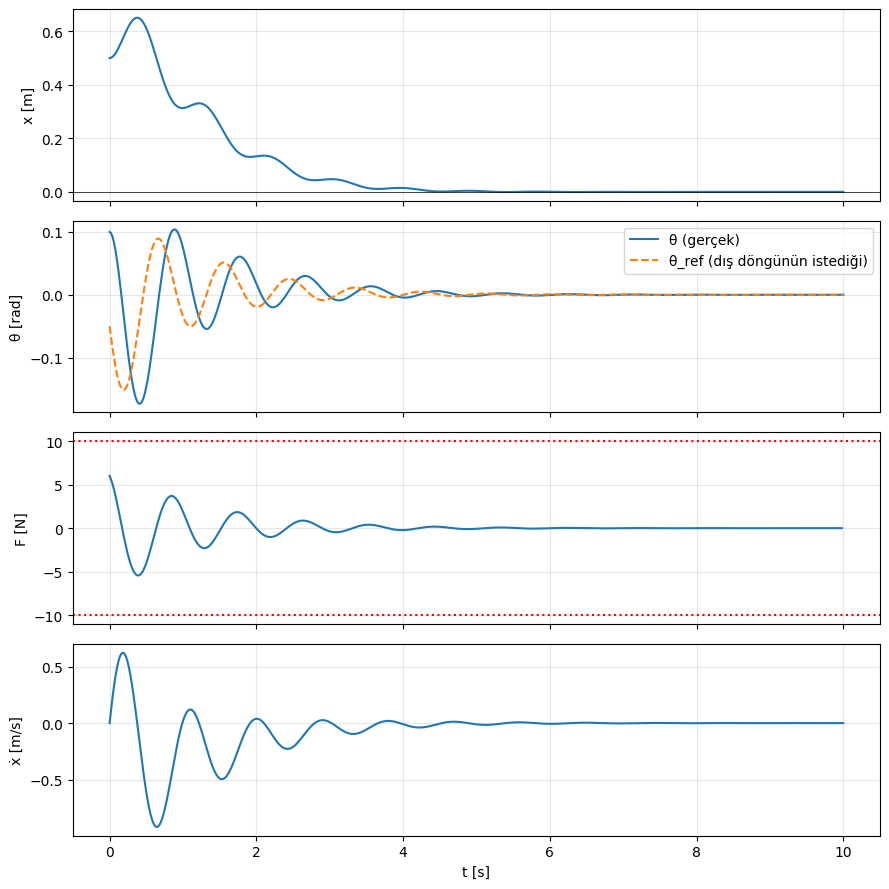

x başlangıç 0.50 → en büyük x 0.651 → son x -0.0000
max |F| = 6.0 N


In [3]:
import importlib, controllers; importlib.reload(controllers)    # controllers.py değişti → yeniden yükle
from controllers import CascadePID, run_closed_loop

# --- Kazançlar ---
kpx, kdx, th_max = 0.1, 0.15, 0.2


ctrl = CascadePID(inner_Kp=40, inner_Kd=5.35, outer_Kp=kpx, outer_Kd=kdx, theta_ref_max=th_max)
s0 = [0.5, 0, 0.1, 0]                     # x₀ = 0.5 m, θ₀ = 0.1 rad  (yol haritasının senaryosu)
t, S, U = run_closed_loop(ctrl, s0, T=10.0, F_max=10.0)

#  θ_ref'i S'den yeniden hesapla 
x, x_dot = S[:, 0], S[:, 1]               # her an için araba konumu ve hızı
theta_ref_t = np.clip(kpx * (0 - x) - kdx * x_dot, -th_max, th_max)

#  Çiz: 4 alt grafik, alt alta 
fig, ax = plt.subplots(4, 1, figsize=(9, 9), sharex=True)

ax[0].plot(t, S[:, 0]);            ax[0].set_ylabel("x [m]")
ax[0].axhline(0, color="k", lw=0.5)

ax[1].plot(t, S[:, 2], label="θ (gerçek)")
ax[1].plot(t, theta_ref_t, "--", label="θ_ref (dış döngünün istediği)")
ax[1].set_ylabel("θ [rad]"); ax[1].legend()

ax[2].plot(t[:-1], U);             ax[2].set_ylabel("F [N]")    # U'da t'den 1 eksik eleman var
ax[2].axhline(10, color="r", ls=":"); ax[2].axhline(-10, color="r", ls=":")

ax[3].plot(t, S[:, 1]);            ax[3].set_ylabel("ẋ [m/s]"); ax[3].set_xlabel("t [s]")

for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"x başlangıç {S[0,0]:.2f} → en büyük x {S[:,0].max():.3f} → son x {S[-1,0]:.4f}")
print(f"max |F| = {np.abs(U).max():.1f} N")